# Notebook 4 — Pemodelan AI/ML untuk Klasifikasi, Clustering, dan Deteksi Anomali Kualitas Air

**Proyek:** Deteksi Pencemaran Limbah pada Sungai Berbasis IoT dan Artificial Intelligence  
**Fokus:** mendeteksi kondisi/pola yang sedang diamati — **bukan memprediksi kondisi air pada masa mendatang**.

Notebook ini melanjutkan hasil Notebook 3. Fitur yang digunakan diselaraskan dengan perangkat keras proyek: `temp_C`, `pH`, dan `turbidity_NTU`.

## Tujuan
1. Membuat baseline klasifikasi terawasi menggunakan label yang tersedia pada dataset.
2. Melakukan clustering untuk melihat pengelompokan pola sensor tanpa memakai label.
3. Mencoba deteksi anomali tanpa label menggunakan Isolation Forest.
4. Membandingkan hasil dan menyimpan model/hasil eksperimen.

> **Batas interpretasi:** dataset sumber bernama `fishpond_dataset_multiclass_2153.csv` dan labelnya adalah `Normal`, `Caution`, `Warning`, `Severe`. Label ini bukan bukti lapangan bahwa sungai tercemar. Hasil klasifikasi mengukur kemampuan model mereproduksi label dataset. Karena label berpotensi berkaitan erat dengan kekeruhan, skor tinggi tidak boleh langsung diklaim sebagai bukti deteksi pencemaran sungai yang akurat. Notebook ini tidak melakukan peramalan waktu.

## 1. Import pustaka

In [1]:
import os, io, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay, silhouette_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import joblib

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
FEATURES = ['temp_C', 'pH', 'turbidity_NTU']
TARGET = 'class'
print('Pustaka berhasil dimuat.')

Pustaka berhasil dimuat.


## 2. Memuat dataset hasil preprocessing

Di Google Colab, unggah file `dataset_eksperimen_sensor.csv` hasil Notebook 3. Jika notebook dijalankan lokal dan file tersedia di folder kerja, notebook akan membacanya langsung.

In [2]:
DATA_PATH = 'dataset_eksperimen_sensor.csv'

if Path(DATA_PATH).exists():
    df = pd.read_csv(DATA_PATH)
    print(f'Membaca file lokal: {DATA_PATH}')
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise ValueError('Tidak ada file yang diunggah.')
        filename = next(iter(uploaded))
        df = pd.read_csv(io.BytesIO(uploaded[filename]))
        print(f'Membaca file unggahan: {filename}')
    except ImportError:
        raise FileNotFoundError('Letakkan dataset_eksperimen_sensor.csv di folder kerja atau unggah melalui Google Colab.')

df.columns = [str(col).strip() for col in df.columns]
missing_cols = [col for col in FEATURES + [TARGET] if col not in df.columns]
if missing_cols:
    raise ValueError(f'Kolom wajib tidak ditemukan: {missing_cols}')
df = df[FEATURES + [TARGET]].copy()
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
print('Ukuran data:', df.shape)
display(df.head())
display(df[TARGET].value_counts().rename_axis('Kelas').to_frame('Jumlah'))

Membaca file lokal: dataset_eksperimen_sensor.csv
Ukuran data: (2153, 4)


,temp_C,pH,turbidity_NTU,class
0,21.86,9.35,130.13,Warning
1,20.17,9.32,52.15,Warning
2,30.10,6.49,35.69,Caution
3,25.51,7.71,17.30,Normal
4,32.56,5.62,132.55,Warning


,Jumlah
Kelas,
Caution,670
Normal,638
Warning,478
Severe,367


## 3. Memahami distribusi label dan fitur

Grafik ini memberikan gambaran data yang digunakan pada eksperimen. Label asli dipertahankan apa adanya; notebook tidak mengubah empat kelas sumber menjadi tiga status proposal secara otomatis karena pemetaan tersebut harus ditetapkan secara eksplisit oleh tim.

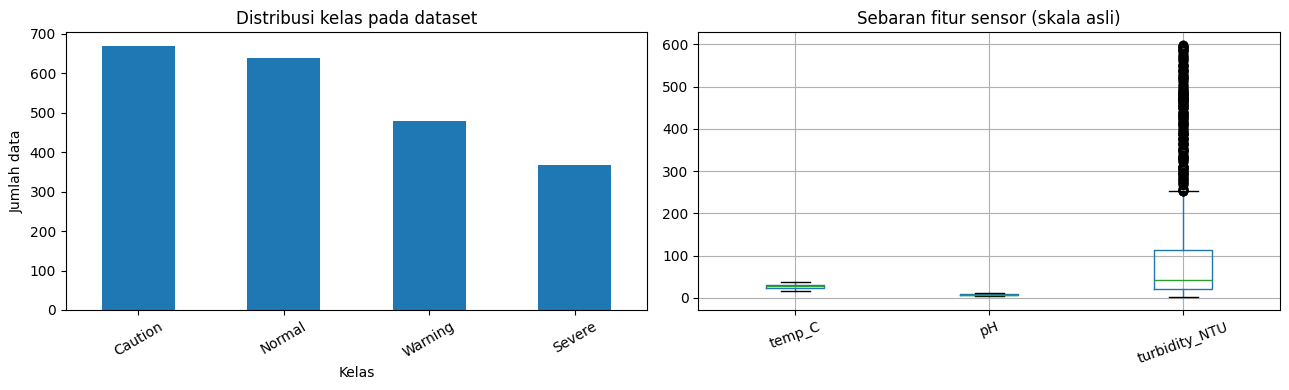

,count,mean,std,min,25%,50%,75%,max
temp_C,2153.0,27.436512,5.193092,15.00,23.85,27.53,31.41,37.99
pH,2153.0,7.556020,1.542629,4.51,6.21,7.57,8.89,10.50
turbidity_NTU,2153.0,101.352982,138.438025,1.02,21.41,41.48,113.93,598.68


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df[TARGET].value_counts().reindex(df[TARGET].value_counts().index).plot(kind='bar', ax=axes[0])
axes[0].set_title('Distribusi kelas pada dataset')
axes[0].set_xlabel('Kelas'); axes[0].set_ylabel('Jumlah data'); axes[0].tick_params(axis='x', rotation=30)
df[FEATURES].boxplot(ax=axes[1])
axes[1].set_title('Sebaran fitur sensor (skala asli)')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

display(df[FEATURES].describe().T)

## 4. Menyiapkan data klasifikasi

Data dibagi menjadi data latih dan data uji secara stratified agar proporsi kelas relatif terjaga. Data uji tidak digunakan saat melatih model. Standardisasi ditempatkan di dalam `Pipeline` untuk mencegah kebocoran informasi dari data uji ke proses scaling.

**Catatan:** pembagian acak ini mengevaluasi reproduksi label pada dataset yang tersedia; tidak membuktikan generalisasi ke sungai/lokasi lain.

In [4]:
X = df[FEATURES].copy()
y = df[TARGET].astype(str).copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)
print('Kelas latih:', sorted(y_train.unique()))

Data latih: (1722, 3) | Data uji: (431, 3)
Kelas latih: ['Caution', 'Normal', 'Severe', 'Warning']


## 5. Melatih dan membandingkan model klasifikasi

Dua kandidat klasifikasi yang disebut dalam proposal dibandingkan: Random Forest dan K-Nearest Neighbors (KNN). Pemilihan baseline dilakukan berdasarkan metrik pada data uji, bukan hanya accuracy.

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Random Forest,1.0000,1.0000,1.0000,1.0000
1,KNN,1.0000,1.0000,1.0000,1.0000


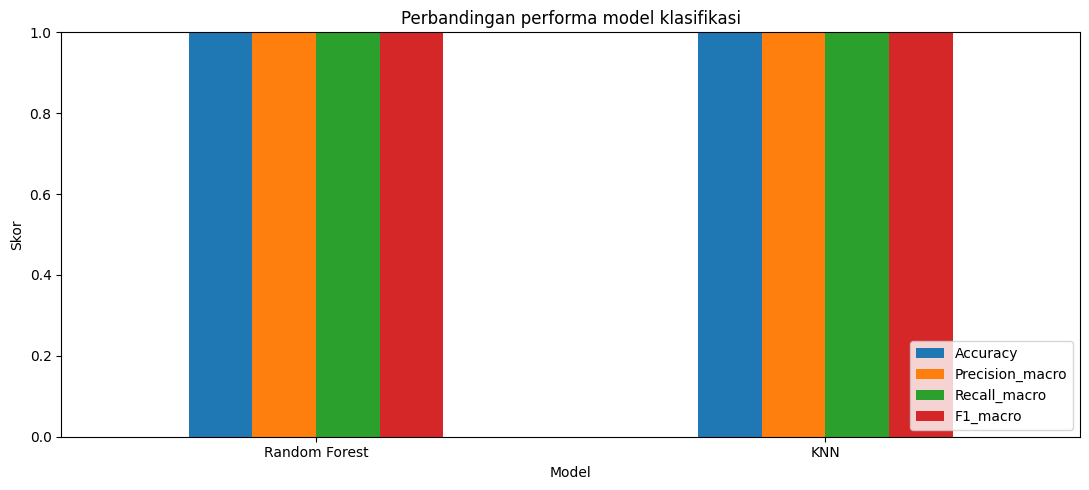

In [5]:
models = {
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                            class_weight='balanced'),
    'KNN': Pipeline([('scaler', StandardScaler()),
                     ('model', KNeighborsClassifier(n_neighbors=7))])
}

results = []
trained_models = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    trained_models[name] = model
    predictions[name] = pred
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision_macro': precision_score(y_test, pred, average='macro', zero_division=0),
        'Recall_macro': recall_score(y_test, pred, average='macro', zero_division=0),
        'F1_macro': f1_score(y_test, pred, average='macro', zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values('F1_macro', ascending=False).reset_index(drop=True)
display(results_df.style.format({col: '{:.4f}' for col in results_df.columns if col != 'Model'}))
ax = results_df.set_index('Model')[['Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro']].plot(
    kind='bar', figsize=(11, 5), ylim=(0, 1), rot=0
)
ax.set_title('Perbandingan performa model klasifikasi')
ax.set_ylabel('Skor'); ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 6. Laporan klasifikasi dan confusion matrix

Gunakan laporan per kelas untuk melihat kelas mana yang paling sering salah diklasifikasikan. Confusion matrix menampilkan jumlah label aktual dibandingkan label keluaran model.

Model baseline dengan F1-macro tertinggi: Random Forest
              precision    recall  f1-score   support

     Caution       1.00      1.00      1.00       134
      Normal       1.00      1.00      1.00       128
      Severe       1.00      1.00      1.00        73
     Warning       1.00      1.00      1.00        96

    accuracy                           1.00       431
   macro avg       1.00      1.00      1.00       431
weighted avg       1.00      1.00      1.00       431



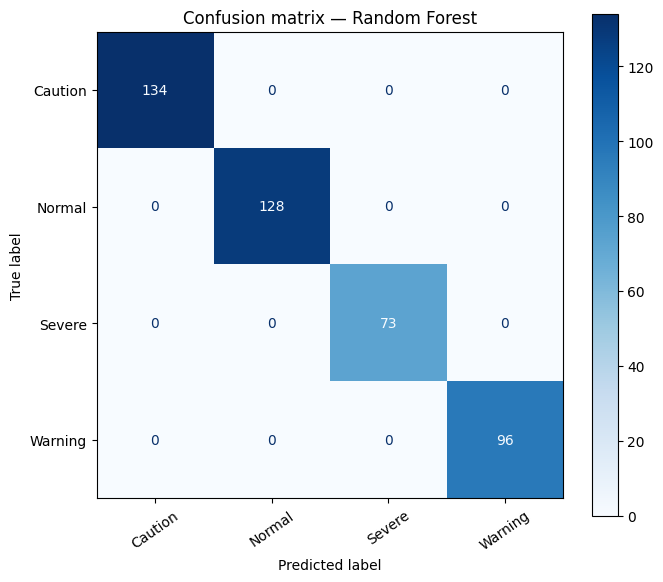

In [6]:
best_name = results_df.loc[0, 'Model']
best_model = trained_models[best_name]
best_pred = predictions[best_name]
print('Model baseline dengan F1-macro tertinggi:', best_name)
print(classification_report(y_test, best_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, ax=ax, cmap='Blues', xticks_rotation=35)
ax.set_title(f'Confusion matrix — {best_name}')
plt.tight_layout(); plt.show()

## 7. Clustering tanpa label menggunakan K-Means

Clustering tidak menggunakan kolom `class`. Fitur distandardisasi, kemudian beberapa nilai K dicoba menggunakan silhouette score sebagai salah satu indikator pemisahan cluster. Skor silhouette bukan bukti bahwa cluster sama dengan kategori pencemaran.

,K,Silhouette
0,2,0.530825
1,3,0.335138
2,4,0.368376
3,5,0.379735
4,6,0.404370


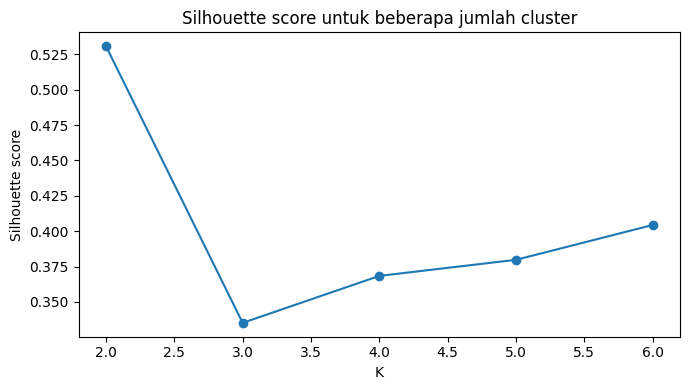

Jumlah cluster yang dipilih berdasarkan silhouette: 2


class,Caution,Normal,Severe,Warning,All
cluster,,,,,
0,0,0,294,0,294
1,670,638,73,478,1859
All,670,638,367,478,2153


In [7]:
scaler_cluster = StandardScaler()
X_scaled = scaler_cluster.fit_transform(df[FEATURES])
cluster_scores = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_k = km.fit_predict(X_scaled)
    cluster_scores.append({'K': k, 'Silhouette': silhouette_score(X_scaled, labels_k)})
cluster_scores_df = pd.DataFrame(cluster_scores)
display(cluster_scores_df)
ax = cluster_scores_df.plot(x='K', y='Silhouette', marker='o', legend=False, figsize=(7, 4))
ax.set_title('Silhouette score untuk beberapa jumlah cluster')
ax.set_ylabel('Silhouette score'); plt.tight_layout(); plt.show()

best_k = int(cluster_scores_df.loc[cluster_scores_df['Silhouette'].idxmax(), 'K'])
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)
df_cluster = df.copy()
df_cluster['cluster'] = cluster_labels
print('Jumlah cluster yang dipilih berdasarkan silhouette:', best_k)
display(pd.crosstab(df_cluster['cluster'], df_cluster[TARGET], margins=True))

## 8. Visualisasi cluster dengan PCA

PCA hanya digunakan untuk memproyeksikan tiga fitur menjadi dua dimensi agar pola cluster lebih mudah dilihat. Visualisasi ini tidak mengubah data asli yang dipakai K-Means.

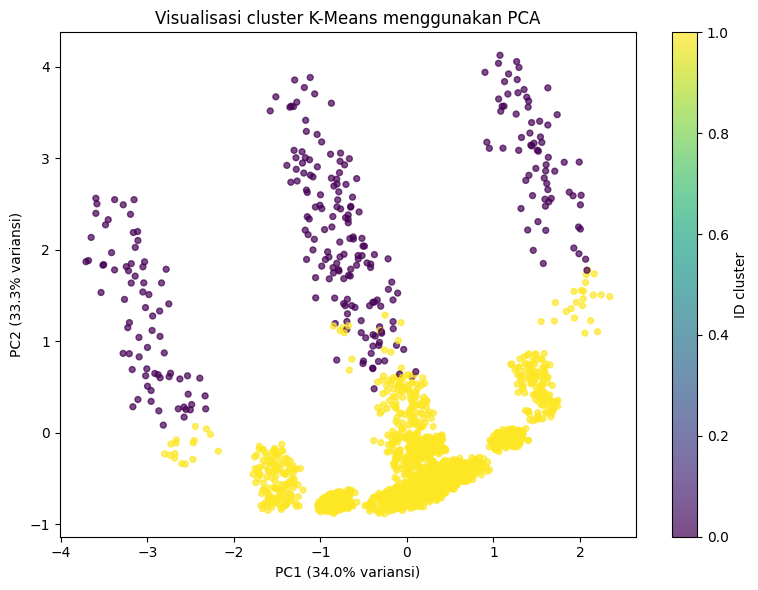

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, s=18, alpha=0.7)
plt.title('Visualisasi cluster K-Means menggunakan PCA')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variansi)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variansi)')
plt.colorbar(scatter, label='ID cluster')
plt.tight_layout(); plt.show()

## 9. Deteksi anomali tanpa label menggunakan Isolation Forest

Isolation Forest menandai sejumlah observasi yang relatif berbeda dari pola mayoritas. Output `-1` berarti kandidat anomali dan `1` berarti tidak ditandai sebagai anomali. Hasil ini adalah **kandidat untuk diperiksa**, bukan keputusan otomatis bahwa air tercemar.

`contamination` di bawah merupakan proporsi awal untuk eksperimen, bukan angka kejadian pencemaran yang diketahui.

Ringkasan deteksi anomali:


,Jumlah
Hasil,
Pola Umum,2045
Kandidat Anomali,108


class,Caution,Normal,Severe,Warning,All
anomaly_flag,,,,,
Kandidat Anomali,0,0,108,0,108
Pola Umum,670,638,259,478,2045
All,670,638,367,478,2153


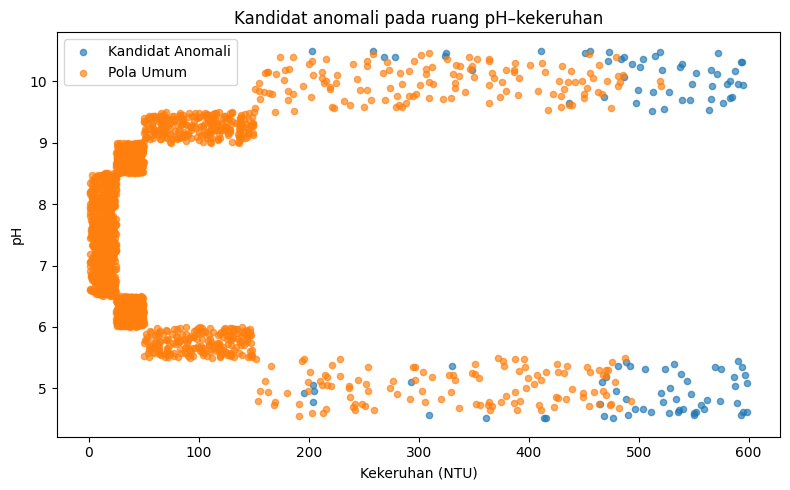

In [9]:
CONTAMINATION = 0.05  # asumsi awal eksperimen; sesuaikan berdasarkan data dan kebutuhan sistem
iso_scaler = StandardScaler()
X_iso = iso_scaler.fit_transform(df[FEATURES])
isolation_model = IsolationForest(contamination=CONTAMINATION,
                                 random_state=RANDOM_STATE, n_estimators=300)
iso_output = isolation_model.fit_predict(X_iso)
df_anomaly = df.copy()
df_anomaly['anomaly_flag'] = np.where(iso_output == -1, 'Kandidat Anomali', 'Pola Umum')
df_anomaly['anomaly_score'] = isolation_model.decision_function(X_iso)
print('Ringkasan deteksi anomali:')
display(df_anomaly['anomaly_flag'].value_counts().rename_axis('Hasil').to_frame('Jumlah'))
display(pd.crosstab(df_anomaly['anomaly_flag'], df_anomaly[TARGET], margins=True))

plt.figure(figsize=(8, 5))
for label, group in df_anomaly.groupby('anomaly_flag'):
    plt.scatter(group['turbidity_NTU'], group['pH'], s=20, alpha=0.65, label=label)
plt.title('Kandidat anomali pada ruang pH–kekeruhan')
plt.xlabel('Kekeruhan (NTU)'); plt.ylabel('pH'); plt.legend(); plt.tight_layout(); plt.show()

## 10. Simpan model dan hasil eksperimen

File keluaran disimpan ke folder kerja. Di Google Colab, unduh file yang diperlukan dari panel Files atau gunakan sel unduhan berikut.

In [10]:
OUTPUT_DIR = Path('output_pemodelan_ai')
OUTPUT_DIR.mkdir(exist_ok=True)

joblib.dump(best_model, OUTPUT_DIR / 'model_klasifikasi_baseline.joblib')
joblib.dump(scaler_cluster, OUTPUT_DIR / 'scaler_clustering.joblib')
joblib.dump(kmeans, OUTPUT_DIR / 'model_kmeans.joblib')
joblib.dump(iso_scaler, OUTPUT_DIR / 'scaler_isolation_forest.joblib')
joblib.dump(isolation_model, OUTPUT_DIR / 'model_isolation_forest.joblib')
results_df.to_csv(OUTPUT_DIR / 'perbandingan_model_klasifikasi.csv', index=False)
df_cluster.to_csv(OUTPUT_DIR / 'hasil_clustering.csv', index=False)
df_anomaly.to_csv(OUTPUT_DIR / 'hasil_deteksi_anomali.csv', index=False)

summary = {
    'best_classification_baseline': best_name,
    'features': FEATURES,
    'target': TARGET,
    'classification_metrics': results_df.iloc[0].to_dict(),
    'selected_k_by_silhouette': best_k,
    'silhouette_scores': cluster_scores_df.to_dict(orient='records'),
    'isolation_forest_contamination_assumption': CONTAMINATION,
    'note': 'Eksperimen mendeteksi/mengklasifikasi pola pada dataset; tidak melakukan prediksi kondisi mendatang.'
}
with open(OUTPUT_DIR / 'ringkasan_eksperimen.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)
print('File keluaran:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print('-', path)

File keluaran:
- output_pemodelan_ai/hasil_clustering.csv
- output_pemodelan_ai/hasil_deteksi_anomali.csv
- output_pemodelan_ai/model_isolation_forest.joblib
- output_pemodelan_ai/model_klasifikasi_baseline.joblib
- output_pemodelan_ai/model_kmeans.joblib
- output_pemodelan_ai/perbandingan_model_klasifikasi.csv
- output_pemodelan_ai/ringkasan_eksperimen.json
- output_pemodelan_ai/scaler_clustering.joblib
- output_pemodelan_ai/scaler_isolation_forest.joblib


## 11. Kesimpulan eksperimen

Isi kesimpulan berdasarkan angka hasil yang benar-benar muncul saat notebook dijalankan:
- Bandingkan Accuracy, Precision macro, Recall macro, dan F1 macro untuk dua kandidat klasifikasi: Random Forest dan KNN.
- Periksa confusion matrix dan laporan per kelas, bukan hanya satu skor.
- Catat jumlah cluster dan silhouette score terpilih, lalu interpretasikan cluster dengan hati-hati.
- Catat jumlah kandidat anomali dari Isolation Forest; kandidat tersebut perlu ditinjau bersama pola sensor dan konteks pengukuran.
- Jangan menyatakan model telah membuktikan pencemaran sungai. Dataset yang digunakan berasal dari konteks fishpond dan label kelas sumber; hasil ini merupakan eksperimen awal yang perlu diuji lagi dengan data sensor proyek.

**Batas ruang lingkup:** seluruh analisis dalam notebook ini adalah klasifikasi kondisi berlabel, clustering pola, dan deteksi anomali. Tidak ada peramalan atau estimasi kondisi air untuk waktu mendatang.